# 04 · What drives value? Reverse-engineering the FIFA 24 price tag

Notebook 03 showed that value is a function of the card alone (club and nationality add nothing). This notebook opens that function up:

1. **The exchange rate of ability**: how much one attribute point is worth.
2. **The age curve**: the same player at different ages.
3. **The pricing grid**: ability × age, the interaction that 02 showed matters.
4. **What each position is paid for** (SHAP by discovered role).
5. **Upgrade ROI**: which +5 attribute upgrade raises a given player's value most.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv").merge(pd.read_csv("../data/roles.csv"), on=["player", "club", "age"])
SKILLS = [c for c in d.columns[6:] if c not in ("value", "value_m", "log_value", "is_gk", "role")]
FEATS = SKILLS + ["height", "weight", "age", "is_gk"]
X, y = d[FEATS], d["log_value"]
model = HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=10,
                                      l2_regularization=1.0, random_state=0).fit(X, y)
print(len(d), "players")

5677 players


## 1. The exchange rate of ability
`reactions` is the best single proxy for the hidden overall rating (03). Within each age group, regress log value on reactions. The slope converts directly into "% value per point" and into **how many points it takes to double a player's price**.

In [2]:
rows = []
for lo, hi in [(17, 21), (22, 25), (26, 29), (30, 33), (34, 45)]:
    s = d[(d.age >= lo) & (d.age <= hi) & (d.is_gk == 0)]
    b = np.polyfit(s.reactions, s.log_value, 1)[0]
    rows.append({"age group": f"{lo}–{hi}", "n": len(s), "% value per +1 reactions": np.expm1(b),
                 "points to double value": np.log(2) / b})
pd.DataFrame(rows).set_index("age group").style.format({"% value per +1 reactions": "{:.1%}",
                                                         "points to double value": "{:.1f}"})

,n,% value per +1 reactions,points to double value
age group,,,
17–21,855,11.4%,6.4
22–25,1575,13.7%,5.4
26–29,1315,14.9%,5.0
30–33,951,15.4%,4.8
34–45,349,14.8%,5.0


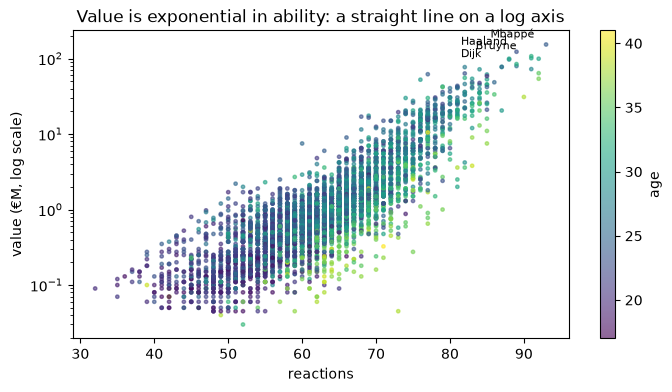

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
s = d[d.is_gk == 0]
sc = ax.scatter(s.reactions, s.value_m, c=s.age, cmap="viridis", s=6, alpha=0.6)
ax.set(yscale="log", xlabel="reactions", ylabel="value (€M, log scale)",
       title="Value is exponential in ability: a straight line on a log axis")
plt.colorbar(sc, label="age")
for n in ["Kylian Mbappé", "Erling Haaland", "Kevin De Bruyne", "Virgil van Dijk"]:
    r = d[d.player == n].iloc[0]
    ax.annotate(n.split()[-1], (r.reactions, r.value_m), fontsize=8, xytext=(-40, 5), textcoords="offset points")

**Price compounds.** Each extra point of `reactions` multiplies value by ~1.11–1.15×, so value roughly **doubles every 5 points**, and the gap between a 75 and an 85 is worth far more than between a 55 and a 65. This is why a linear model on raw euros cannot fit well.

## 2. The age curve: the same player at different ages
Partial dependence: take every player, set their age to *a* while keeping their attributes, and record the predicted value relative to the same player at 27. Split by ability tier.

,19,23,27,30,32,34,36
reactions < 60,×0.90,×1.06,×1.00,×0.92,×0.79,×0.67,×0.33
60–70,×0.95,×1.06,×1.00,×0.92,×0.80,×0.58,×0.36
70–80,×0.99,×1.05,×1.00,×0.93,×0.82,×0.56,×0.37
> 80,×1.02,×1.06,×1.00,×0.93,×0.86,×0.64,×0.47


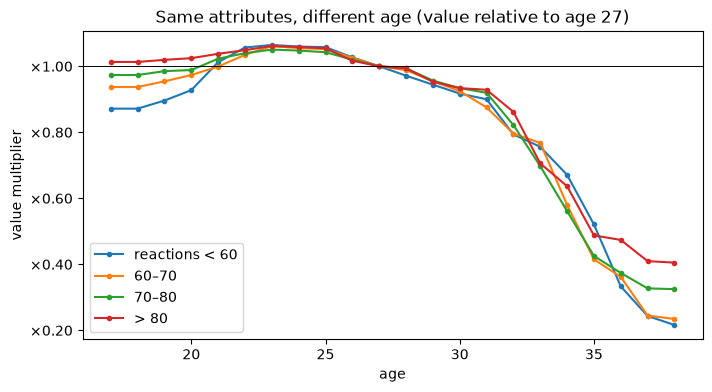

In [4]:
ages = np.arange(17, 39)
tiers = {"reactions < 60": d.reactions < 60, "60–70": d.reactions.between(60, 70),
         "70–80": d.reactions.between(71, 80), "> 80": d.reactions > 80}
curves = {}
for name, mask in tiers.items():
    sub = X[mask & (d.is_gk == 0)]
    ref = model.predict(sub.assign(age=27))
    curves[name] = [np.median(np.exp(model.predict(sub.assign(age=a)) - ref)) for a in ages]
curves = pd.DataFrame(curves, index=ages)
ax = curves.plot(figsize=(8, 4), title="Same attributes, different age (value relative to age 27)", marker=".")
ax.axhline(1, color="k", lw=0.7)
ax.set(xlabel="age", ylabel="value multiplier")
ax.yaxis.set_major_formatter(lambda v, _: f"×{v:.2f}")
curves.loc[[19, 23, 27, 30, 32, 34, 36]].T.style.format("×{:.2f}")

* Holding attributes fixed, value **peaks around 23–25** and is roughly flat until ~29.
* Then it falls off a cliff: a 34-year-old is worth about **half** what the identical 27-year-old is, and a 36-year-old about a third.
* Young players get only a small premium for the *same current* attributes: a 19-year-old is priced about the same as an identical 27-year-old. The steep part of the curve is decline, not youth.

## 3. The pricing grid: ability × age
A two-feature model (reactions, age) as a readable price list. Because pricing is multiplicative, age discounts in euros grow with ability: the interaction that degree-2 Ridge and boosting capture.

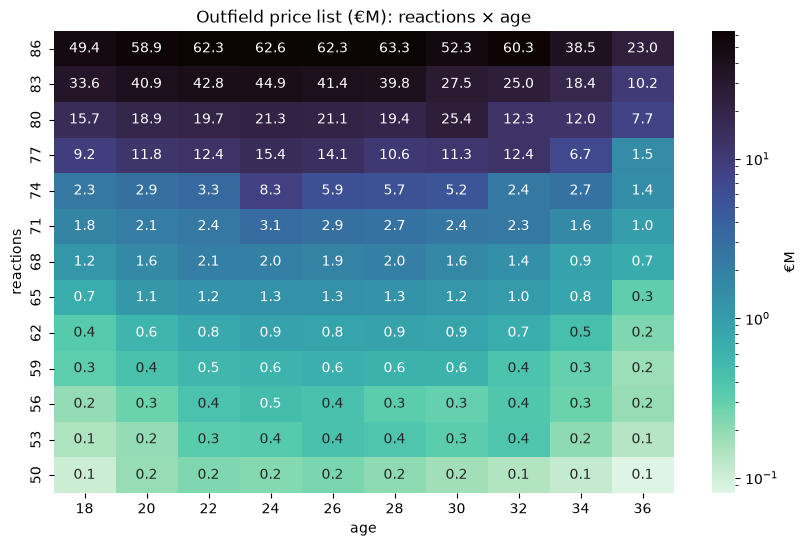

In [5]:
grid_model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(
    d.loc[d.is_gk == 0, ["reactions", "age"]], d.loc[d.is_gk == 0, "log_value"])
R, A = np.arange(50, 87, 3), np.arange(18, 37, 2)  # above ~86 the tree model plateaus (few players)
grid = pd.DataFrame([[np.exp(grid_model.predict([[r, a]])[0]) / 1e6 for a in A] for r in R], index=R, columns=A)
plt.figure(figsize=(10, 6))
sns.heatmap(grid.iloc[::-1], annot=True, fmt=".1f", cmap="mako_r", norm=plt.matplotlib.colors.LogNorm(),
            cbar_kws={"label": "€M"})
plt.title("Outfield price list (€M): reactions × age")
plt.xlabel("age")
plt.ylabel("reactions");

## 4. What does each position get paid for?
SHAP decomposes each prediction into per-attribute contributions (on the log scale, so a contribution of +0.1 ≈ +10.5% value). Ranking the mean |SHAP| *within each discovered role* shows which attributes the valuation formula rewards for that position.

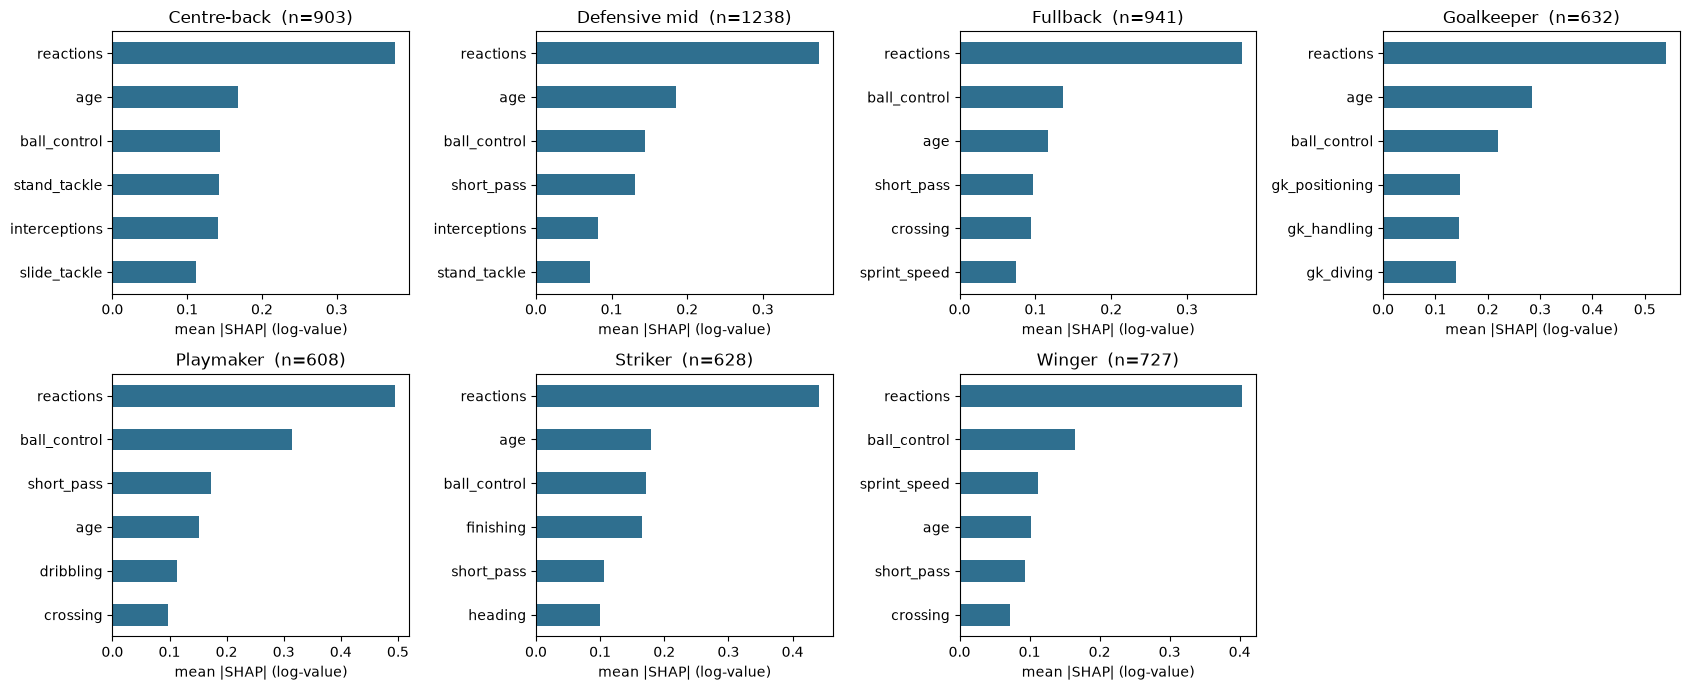

In [6]:
explainer = shap.TreeExplainer(model)
sv = pd.DataFrame(explainer.shap_values(X), columns=FEATS, index=d.index)
imp = sv.abs().groupby(d.role).mean().drop(columns=["is_gk"])
top = {r: imp.loc[r].nlargest(6) for r in imp.index}
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (r, s) in zip(axes.flat, top.items()):
    s[::-1].plot.barh(ax=ax, color="#2f6f8f")
    ax.set_title(f"{r}  (n={(d.role == r).sum()})")
    ax.set_xlabel("mean |SHAP| (log-value)")
axes.flat[-1].axis("off")
plt.tight_layout()

`ball_control` ranks near the top for *every* role, including goalkeepers. Like `reactions` and `composure`, it behaves as a general-quality proxy, not a positional skill. Excluding those and age, what is left is what each role is *specifically* paid for:

In [7]:
generic = {"age", "reactions", "composure", "ball_control"}
pd.DataFrame({r: [f for f in imp.loc[r].sort_values(ascending=False).index if f not in generic][:4]
              for r in imp.index}, index=["#1", "#2", "#3", "#4"]).T

,#1,#2,#3,#4
Centre-back,stand_tackle,interceptions,slide_tackle,short_pass
Defensive mid,short_pass,interceptions,stand_tackle,crossing
Fullback,short_pass,crossing,sprint_speed,stamina
Goalkeeper,gk_positioning,gk_handling,gk_diving,gk_reflexes
Playmaker,short_pass,dribbling,crossing,finishing
Striker,finishing,short_pass,heading,att_position
Winger,sprint_speed,short_pass,crossing,dribbling


### Why is Mbappé worth €153.5M? One prediction decomposed

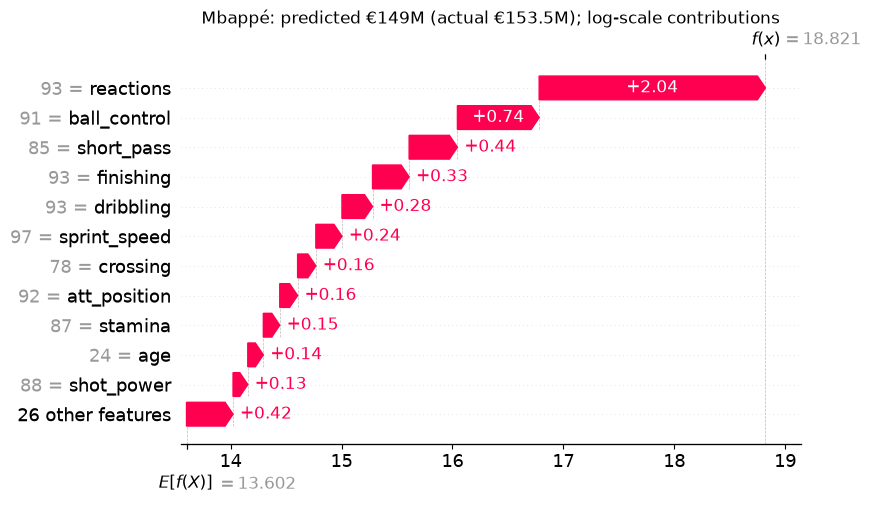

In [8]:
i = d.index[d.player == "Kylian Mbappé"][0]
wax = shap.plots.waterfall(shap.Explanation(sv.loc[i].values, float(np.ravel(explainer.expected_value)[0]), X.loc[i].values, feature_names=FEATS),
                     max_display=12, show=False)
wax.set_title(f"Mbappé: predicted €{np.exp(model.predict(X.loc[[i]])[0]) / 1e6:.0f}M "
          f"(actual €{d.value_m[i]:.1f}M); log-scale contributions")
wfig = wax.figure
wfig.set_size_inches(8, 5)
display(wfig)
plt.close(wfig)

## 5. Upgrade ROI: which +5 is worth the most?
A counterfactual question no correlation table can answer: *for this specific player*, if one attribute went up by 5 points, how much would their value rise? This is the model used as a simulator.

In [9]:
def upgrade_roi(name, step=5, top=8):
    i = d.index[d.player == name][0]
    base = model.predict(X.loc[[i]])[0]
    cand = [c for c in SKILLS if not (c.startswith("gk_") ^ bool(d.is_gk[i]))] + (["reactions"] if d.is_gk[i] else [])
    gains = {}
    for c in cand:
        x = X.loc[[i]].copy()
        x[c] = min(x[c].iloc[0] + step, 99)
        gains[c] = np.exp(model.predict(x)[0] - base) - 1
    g = pd.Series(gains).nlargest(top)
    return pd.DataFrame({"current": X.loc[i, g.index].astype(int), f"value change if +{step}": g,
                         "≈ € gain": (g * np.exp(base)).round(-4)})


for name in ["Bukayo Saka", "Rodri", "Alex Meret", "Gianluigi Donnarumma"]:
    r = d[d.player == name].iloc[0]
    print(f"\n{name}  ({r.role}, age {r.age}, €{r.value_m}M)")
    display(upgrade_roi(name).style.format({"value change if +5": "{:+.1%}", "≈ € gain": "€{:,.0f}"}))


Bukayo Saka  (Playmaker, age 21, €47.5M)


,current,value change if +5,≈ € gain
reactions,84,+35.4%,"€16,840,000"
sprint_speed,82,+14.9%,"€7,070,000"
short_pass,81,+14.5%,"€6,890,000"
finishing,81,+8.1%,"€3,870,000"
crossing,81,+7.4%,"€3,540,000"
interceptions,68,+4.7%,"€2,260,000"
ball_control,85,+3.6%,"€1,720,000"
stamina,80,+1.7%,"€830,000"



Rodri  (Defensive mid, age 27, €77.0M)


,current,value change if +5,≈ € gain
reactions,82,+31.4%,"€23,760,000"
heading,80,+7.9%,"€6,010,000"
strength,84,+5.2%,"€3,910,000"
ball_control,85,+2.7%,"€2,010,000"
crossing,63,+1.8%,"€1,340,000"
fk_acc,61,+1.0%,"€760,000"
slide_tackle,78,+1.0%,"€760,000"
long_pass,83,+0.8%,"€620,000"



Alex Meret  (Goalkeeper, age 26, €17.0M)


,current,value change if +5,≈ € gain
reactions,74,+17.1%,"€2,890,000"
gk_kicking,70,+7.9%,"€1,330,000"
gk_positioning,80,+4.6%,"€770,000"
gk_handling,76,+0.1%,"€20,000"
gk_diving,80,+0.0%,€0
gk_reflexes,84,+0.0%,€0



Gianluigi Donnarumma  (Goalkeeper, age 24, €78.0M)


,current,value change if +5,≈ € gain
gk_positioning,85,+0.0%,€0
gk_diving,90,+0.0%,€0
gk_handling,83,+0.0%,€0
gk_kicking,79,+0.0%,€0
gk_reflexes,89,+0.0%,€0
reactions,85,+0.0%,€0


## Takeaways
* **Exponential pricing.** Each point of `reactions` compounds value by ~11–15% (a little less for teenagers). Value doubles every ~5 points.
* **The age cliff** starts around 30 and roughly halves a player's value by 34, *for identical attributes*.
* **Positions are paid for different things.** The formula rewards defenders for tackling and interceptions, goalkeepers for reflexes and diving, and attackers for finishing and positioning. These role-dependent effects only appear when the roles are separated (05).
* **Upgrade ROI is player-specific.** The most valuable improvement depends on the role and on where the player sits on the curve, so a one-size-fits-all coefficient misleads.
* **Limitation, visible in the Donnarumma row:** for players already at the top of an attribute's range, tree models predict a flat 0% gain, because they cannot extrapolate past the best players they have seen. The same ceiling motivated the Ridge blend in 02. Upgrade ROI is reliable inside the bulk of the data, not at its frontier.